In [1]:
# Installing the Box2D environment for physics simulation
!pip install gymnasium
!pip install swig
!pip install gymnasium[box2d]
!pip install gymnasium[other]

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: C:\Users\riwki\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: C:\Users\riwki\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: C:\Users\riwki\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: C:\Users\riwki\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [2]:
# Updating the package list and installing necessary packages for the project
!sudo apt-get install -y cmake
# Updating the package list and installing ffmpeg and freeglut3-dev for visualization, xvfb for virtual display
!sudo apt-get install -y ffmpeg freeglut3-dev xvfb

# Installing the Stable Baselines3 library for reinforcement learning along with extra dependencies
!pip install "stable-baselines3[extra]>=2.0.0a4"

Sudo is disabled on this machine. To enable it, go to the ]8;;ms-settings:developers\Developer Settings page]8;;\ in the Settings app
Sudo is disabled on this machine. To enable it, go to the ]8;;ms-settings:developers\Developer Settings page]8;;\ in the Settings app


Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: C:\Users\riwki\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


## Importing required libraries and modules

In [3]:
import os
import torch.nn as nn
from collections import OrderedDict
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import gymnasium as gym
import base64


from stable_baselines3 import PPO
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.callbacks import BaseCallback
from stable_baselines3.common.results_plotter import load_results, ts2xy
from stable_baselines3.common.vec_env import VecNormalize, DummyVecEnv, VecVideoRecorder

from IPython import display as ipythondisplay

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


## Setting up a Virtual Display

In [4]:
os.system("Xvfb :1 -screen 0 1024x768x24 &")
os.environ['DISPLAY'] = ':1'

## Callback for Model Checkpointing

In [5]:
class SaveOnIntervalCallback(BaseCallback):
    def __init__(self, save_interval: int, save_path: str, verbose=1):
        super().__init__(verbose)
        self.save_interval = save_interval
        self.save_path = save_path

    def _on_step(self) -> bool:
        if self.num_timesteps % self.save_interval == 0:
            save_file = os.path.join(self.save_path, f'model_{self.num_timesteps}')
            self.model.save(save_file)
            if self.verbose > 0:
                print(f'Saving model to {save_file}.zip')
        return True

In [6]:
# Creating directories for storing logs and models
log_dir = "cartpolePPO/gym/"  # Directory for storing training logs
models_dir = "cartpolePPO/models/"  # Directory for storing models

# Ensuring the directories exist or creating them
os.makedirs(log_dir, exist_ok=True)
os.makedirs(models_dir, exist_ok=True)


## Configuration and Environment Initialization

In [7]:
# Define hyper parameters for PPO
config = OrderedDict([
    ("n_steps", 2048),
    ("ent_coef", 0.01),
    ("learning_rate", 3e-4),
    ("batch_size", 64),
    ("n_epochs", 10),
    ("n_timesteps", 1000000),
    ("normalize", False)
])

In [8]:
env = gym.make("CartPole-v1")  # Creating the environment

env = Monitor(env, log_dir)
env = DummyVecEnv([lambda: env])
if config['normalize']:
  env = VecNormalize(env, norm_obs=config['normalize_kwargs']['norm_obs'], norm_reward=config['normalize_kwargs']['norm_reward'], clip_obs=10.0)

## Define Custom Feature Extractor and Create PPO Model

In [ ]:
import torch as th
import torch.nn as nn

from stable_baselines3.common.torch_layers import BaseFeaturesExtractor

class CustomANN(BaseFeaturesExtractor):
    def __init__(self, observation_space, features_dim=128):
        super().__init__(observation_space, features_dim)

        input_dim = observation_space.shape[0]

        self.network = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Linear(128, features_dim),
            nn.ReLU()
        )

    def forward(self, observations):
        return self.network(observations)

policy_kwargs = dict(
    features_extractor_class=CustomANN,
    features_extractor_kwargs=dict(features_dim=64),
    net_arch=[128, 128]
)

## Model Initialization and Training

In [10]:
# Create the PPO model
model = PPO(
    "MlpPolicy",
    env,
    n_steps=config['n_steps'],
    ent_coef=config['ent_coef'],
    learning_rate=config['learning_rate'],
    batch_size=config['batch_size'],
    n_epochs=config['n_epochs'],
    verbose=1,
    policy_kwargs=policy_kwargs,
)

save_interval = 200000
callback = SaveOnIntervalCallback(save_interval, save_path=models_dir)

Using cuda device


C:\Users\riwki\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\stable_baselines3\common\on_policy_algorithm.py:150: UserWarning: You are trying to run PPO on the GPU, but it is primarily intended to run on the CPU when not using a CNN policy (you are using ActorCriticPolicy which should be a MlpPolicy). See https://github.com/DLR-RM/stable-baselines3/issues/1245 for more info. You can pass `device='cpu'` or `export CUDA_VISIBLE_DEVICES=` to force using the CPU.Note: The model will train, but the GPU utilization will be poor and the training might take longer than on CPU.
  warnings.warn(


In [ ]:
# Start the training
model.learn(
    total_timesteps=config["n_timesteps"],
    callback=callback
)

---------------------------------
| rollout/           |          |
|    ep_len_mean     | 23.6     |
|    ep_rew_mean     | 23.6     |
| time/              |          |
|    fps             | 351      |
|    iterations      | 1        |
|    time_elapsed    | 5        |
|    total_timesteps | 2048     |
---------------------------------
---------------------------------------
| rollout/                |           |
|    ep_len_mean          | 28.9      |
|    ep_rew_mean          | 28.9      |
| time/                   |           |
|    fps                  | 265       |
|    iterations           | 2         |
|    time_elapsed         | 15        |
|    total_timesteps      | 4096      |
| train/                  |           |
|    approx_kl            | 0.0130315 |
|    clip_fraction        | 0.11      |
|    clip_range           | 0.2       |
|    entropy_loss         | -0.685    |
|    explained_variance   | -0.00291  |
|    learning_rate        | 0.0003    |
|    loss           

## Save Model and Normalization Data

In [11]:
# Save the final model
model.save(os.path.join(models_dir, "model_final"))

## Utility Functions

### Record Video

In [12]:
# Function to record videos of the agent's performance
def record_video(env_id, model, video_length=5000, prefix="", video_folder="cartpolePPO/videos/"):
    eval_env = DummyVecEnv([lambda: gym.make(env_id, render_mode='rgb_array')])
    eval_env = VecVideoRecorder(
        eval_env,
        video_folder=video_folder,
        record_video_trigger=lambda step: step == 0,
        video_length=video_length,
        name_prefix=prefix,
    )
    obs = eval_env.reset()
    for _ in range(video_length):
        action, _ = model.predict(obs, deterministic=True)
        obs, _, _, _ = eval_env.step(action)
    eval_env.close()

### Show Video

In [13]:
# Function to display recorded videos
def show_videos(video_path="", prefix=""):
    html = []
    for mp4 in Path(video_path).glob("{}*.mp4".format(prefix)):
        video_b64 = base64.b64encode(mp4.read_bytes())
        html.append(
            '''<video alt="{0}" autoplay
                      loop controls style="height: 400px;">
                <source src="data:video/mp4;base64,{1}" type="video/mp4" />
            </video>'''.format(mp4, video_b64.decode('ascii'))
        )
    ipythondisplay.display(ipythondisplay.HTML(data="<br>".join(html)))

## Function to View Model Performance

In [14]:
# Functions for analyzing the trained models

def get_model_identifiers(models_dir):
    files = os.listdir(models_dir)
    identifiers = []
    for f in files:
        if f.startswith("model_") and f != "model_final.zip":
            identifier = f.replace("model_", "").replace(".zip", "")
            if identifier.isdigit():
                identifiers.append(int(identifier))

    return sorted(identifiers)

# Function to find key identifiers (earliest, middle, final)
def find_key_identifiers(identifiers):
    earliest = identifiers[0]
    middle = identifiers[len(identifiers) // 2]
    final = identifiers[-1]
    return earliest, middle, final

# Function to view videos of the models at different training stages
def view(models_dir):
    identifiers = get_model_identifiers(models_dir)  # Getting model identifiers
    earliest, middle, final = find_key_identifiers(identifiers)  # Finding key identifiers

    # Recording and displaying videos at the beginning, middle, and end of training
    for stage, identifier in zip(["beginning", "middle", "end"], [earliest, middle, final]):
        model_path = os.path.join(models_dir, f'model_{identifier}')  # Forming the model path
        model = PPO.load(model_path)  # Loading the model
        record_video("CartPole-v1", model, video_length=2000, prefix=f'ppo-cartpole-{stage}')  # Recording video
        show_videos("cartpolePPO/videos/", prefix=f'ppo-cartpole-{stage}')  # Showing videos

## Record and Display Videos

In [15]:
# Display the video created at different stages of trained model
view(models_dir)

Saving video to d:\Project\assignment2\cartpolePPO\videos\ppo-cartpole-beginning-step-0-to-step-2000.mp4
MoviePy - Building video d:\Project\assignment2\cartpolePPO\videos\ppo-cartpole-beginning-step-0-to-step-2000.mp4.
MoviePy - Writing video d:\Project\assignment2\cartpolePPO\videos\ppo-cartpole-beginning-step-0-to-step-2000.mp4



MoviePy - Done !
MoviePy - video ready d:\Project\assignment2\cartpolePPO\videos\ppo-cartpole-beginning-step-0-to-step-2000.mp4


Saving video to d:\Project\assignment2\cartpolePPO\videos\ppo-cartpole-middle-step-0-to-step-2000.mp4
MoviePy - Building video d:\Project\assignment2\cartpolePPO\videos\ppo-cartpole-middle-step-0-to-step-2000.mp4.
MoviePy - Writing video d:\Project\assignment2\cartpolePPO\videos\ppo-cartpole-middle-step-0-to-step-2000.mp4



MoviePy - Done !
MoviePy - video ready d:\Project\assignment2\cartpolePPO\videos\ppo-cartpole-middle-step-0-to-step-2000.mp4


Saving video to d:\Project\assignment2\cartpolePPO\videos\ppo-cartpole-end-step-0-to-step-2000.mp4
MoviePy - Building video d:\Project\assignment2\cartpolePPO\videos\ppo-cartpole-end-step-0-to-step-2000.mp4.
MoviePy - Writing video d:\Project\assignment2\cartpolePPO\videos\ppo-cartpole-end-step-0-to-step-2000.mp4



MoviePy - Done !
MoviePy - video ready d:\Project\assignment2\cartpolePPO\videos\ppo-cartpole-end-step-0-to-step-2000.mp4


## Plot the learning curve

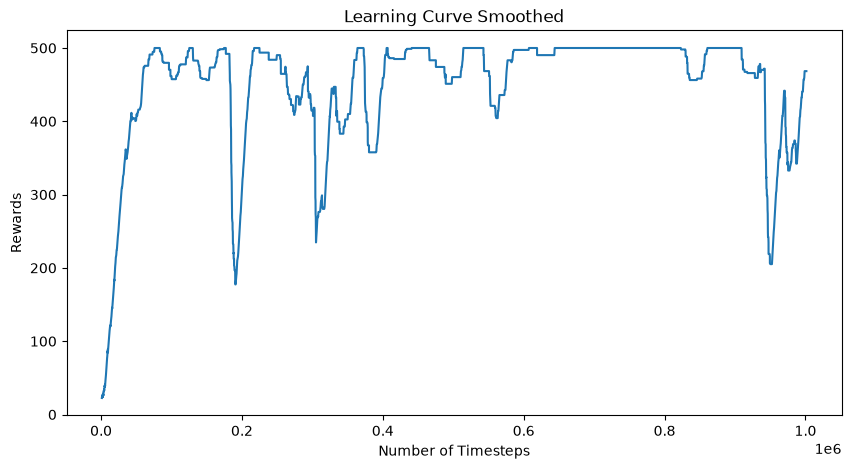

In [16]:
# Function for plotting the learning curve of the agent
def plot_results(log_folder, title="Learning Curve"):
    x, y = ts2xy(load_results(log_folder), "timesteps")
    y = np.convolve(y, np.ones((50,))/50, mode='valid')
    x = x[len(x) - len(y):]
    plt.figure(figsize=(10,5))
    plt.plot(x, y)
    plt.xlabel("Number of Timesteps")
    plt.ylabel("Rewards")
    plt.title(title + " Smoothed")
    plt.show()
 
plot_results(log_dir)

In [17]:
import gymnasium as gym
from stable_baselines3 import PPO
from stable_baselines3.common.evaluation import evaluate_policy

eval_env = gym.make("CartPole-v1")

model = PPO.load("CartpolePPO/models/model_final.zip")

mean_reward, std_reward = evaluate_policy(
    model,
    eval_env,
    n_eval_episodes=20,
    deterministic=True
)

print(f"Average Episode Reward: {mean_reward:.2f}")
print(f"Standard Deviation: {std_reward:.2f}")

eval_env.close()

C:\Users\riwki\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\stable_baselines3\common\on_policy_algorithm.py:150: UserWarning: You are trying to run PPO on the GPU, but it is primarily intended to run on the CPU when not using a CNN policy (you are using ActorCriticPolicy which should be a MlpPolicy). See https://github.com/DLR-RM/stable-baselines3/issues/1245 for more info. You can pass `device='cpu'` or `export CUDA_VISIBLE_DEVICES=` to force using the CPU.Note: The model will train, but the GPU utilization will be poor and the training might take longer than on CPU.
  warnings.warn(
C:\Users\riwki\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\stable_baselines3\common\evaluation.py:71: UserWarning: Evaluation environment is not wrapped with a ``Monitor`` wrapper. This may result in reporting modified episode lengths and rewards, i

Average Episode Reward: 500.00
Standard Deviation: 0.00
